Будем предсказывать **quality** по химическим характеристикам вина и признаку **is_red**. Данные для красного и белого вин объединим так же, как раньше.

В первой работе я уже подбирал `alpha` у Ridge на одной валидационной выборке. Здесь сравним полный и случайный поиск с кросс-валидацией. Возьмём ранее использованный случайный лес: у него можно исследовать три содержательных ограничения сложности, не добавляя настройки только ради количества.


In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import randint, uniform
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import (
    GroupKFold, GroupShuffleSplit, GridSearchCV,
    ParameterGrid, RandomizedSearchCV, cross_validate,
)

random_state = 42
scoring = 'neg_root_mean_squared_error'
n_folds = 5
n_jobs = 4
sns.set_style('whitegrid')


# Подготовка данных

Используем те же csv-файлы. Значение `is_red = 1` обозначает красное вино, `is_red = 0` — белое. Повторять весь первичный анализ из первой ЛР не будем: сейчас интересует влияние настроек одной модели.


In [2]:
root = Path.cwd()
if not (root / 'regression').is_dir():
    root = root.parent
data_dir = root / 'regression' / 'data' / 'wine+quality'

red_wine = pd.read_csv(data_dir / 'winequality-red.csv', sep=';').assign(is_red=1)
white_wine = pd.read_csv(data_dir / 'winequality-white.csv', sep=';').assign(is_red=0)
df = pd.concat([red_wine, white_wine], ignore_index=True)
X = df.drop(columns='quality')
y = df['quality']

print('Размер датасета:', df.shape)
print('Полные повторы строк:', df.duplicated().sum())


Размер датасета: (6497, 13)
Полные повторы строк: 1177


Как и в первой работе, одинаковые наборы признаков объединим в группы. Сохраним прежнее разбиение: 80% групп для обучения, 20% — для финальной оценки. Иначе копии одного образца могут оказаться по обе стороны разбиения и сделать результат слишком оптимистичным.

Этот локальный test уже использовался в первой ЛР, поэтому он не является новой независимой проверкой. В этой работе по нему не меняем ни пространство поиска, ни выбранную модель.


In [3]:
groups = X.groupby(list(X.columns), sort=False, dropna=False).ngroup()
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=random_state)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train = groups.iloc[train_idx]

print('Обучение:', X_train.shape, '| Test:', X_test.shape)


Обучение: (5210, 12) | Test: (1287, 12)


# Кросс-валидация

Одно разбиение даёт результат, зависящий от конкретных объектов в validation. При кросс-валидации каждая часть обучающей выборки по очереди становится валидационной. Так сравним среднюю ошибку и её разброс на нескольких разбиениях.

Выберу **5 folds**: в каждом обучении останется примерно 80% обучающих данных, а вычислительная стоимость будет в пять раз выше одного запуска, что приемлемо для небольшой сетки. Используем `GroupKFold` с перемешиванием групп: одинаковые признаки останутся вместе и внутри CV. Список разбиений заранее зафиксируем для всех кандидатов.

Если многократно выбирать настройки по test, мы постепенно подстроимся под случайные особенности его ответов. Такая метрика перестанет честно оценивать обобщение. Поэтому все решения ниже принимаю по CV, а test использую после выбора настроек.

Основная метрика — RMSE, как в первой ЛР. Она выражена в баллах качества и сильнее штрафует крупные ошибки. `sklearn` максимизирует score, поэтому задаём `neg_root_mean_squared_error`; в таблицах покажем обычный положительный RMSE, где меньше — лучше.


In [4]:
cv = GroupKFold(n_splits=n_folds, shuffle=True, random_state=random_state)
folds = list(cv.split(X_train, y_train, groups_train))

display(pd.DataFrame([
    {'Fold': i, 'Train': len(train), 'Validation': len(val)}
    for i, (train, val) in enumerate(folds, 1)
]).set_index('Fold'))


,Train,Validation
Fold,,
1,4162,1048
2,4188,1022
3,4167,1043
4,4162,1048
5,4161,1049


# Исходная модель

Baseline этой работы — случайный лес из первой ЛР: **300 деревьев**, минимум **2 объекта в листе**, **80% признаков** при разбиении, без ограничения глубины. Остальные параметры оставим стандартными. `random_state = 42` фиксирует случайность, `n_jobs` влияет на выполнение, а не на сложность модели.

Это уже обучаемая модель, а не постоянный прогноз из первой работы. Её настройки теперь зафиксированы до поиска. Веса и пороги разбиений лес выучит сам, а ограничения деревьев задаём мы — это и есть гиперпараметры.

Лесу не требуется масштабирование: деревья сравнивают значения признаков с порогами. Поэтому отдельного преобразования данных здесь нет.


In [5]:
baseline = RandomForestRegressor(
    n_estimators=300, max_depth=None, min_samples_leaf=2,
    max_features=0.8, random_state=random_state, n_jobs=1,
)

baseline_cv = cross_validate(
    baseline, X_train, y_train, cv=folds, scoring=scoring,
    return_train_score=True, n_jobs=n_jobs, error_score='raise',
)
print(f"Baseline Train RMSE: {-baseline_cv['train_score'].mean():.4f}")
print(f"Baseline CV RMSE: {-baseline_cv['test_score'].mean():.4f}")
print(f"Разброс по folds: {baseline_cv['test_score'].std():.4f}")


Baseline Train RMSE: 0.2897
Baseline CV RMSE: 0.6936
Разброс по folds: 0.0160


Исходный лес получил Train RMSE = 0.2897, CV RMSE = 0.6936, стандартное отклонение = 0.0160. На обучающих объектах ошибка существенно меньше. Значит, модель сильно подстраивается под train; при подборе будем смотреть, удастся ли улучшить обобщение, а не только обучающую метрику.

# Пространство поиска

Число деревьев оставлю равным 300, чтобы стоимость одной попытки была сопоставимой. Менять будем три параметра:

| Гиперпараметр | Смысл | Grid Search | Random Search | Ожидаемое влияние |
|---|---|---|---|---|
| `max_depth` | Максимальная глубина дерева | 3, 10, None | 3, 5, 10, 20, None | Маленькая глубина упрощает правила и может привести к недообучению; большая позволяет точнее подстроиться под train |
| `min_samples_leaf` | Минимум обучающих строк в листе | 1, 2, 8 | Целые от 1 до 8 | Большой лист сглаживает прогноз; маленький позволяет выделять редкие сочетания и шум |
| `max_features` | Доля признаков, рассматриваемых при разбиении | 0.5, 0.8, 1.0 | Равномерно от 0.5 до 1.0 | Меньшая доля увеличивает разнообразие деревьев, но может ослабить отдельное дерево; большая даёт больше выбора, но может сделать деревья похожими |

`None` означает отсутствие ограничения глубины. В сетку включены исходные настройки. Диапазоны случайного поиска покрывают ту же область, но содержат промежуточные значения: сравним стратегии при одинаковом количестве попыток. `uniform(0.5, 0.5)` задаёт интервал [0.5, 1.0), а `randint(1, 9)` — целые 1–8.

Для глубины и размера листа выбраны намеренно разные уровни сложности. У `max_features` доля переводится в целое число признаков, поэтому разные случайные значения иногда дают одинаковое фактическое число признаков.


In [6]:
param_grid = {
    'max_depth': [3, 10, None],
    'min_samples_leaf': [1, 2, 8],
    'max_features': [0.5, 0.8, 1.0],
}
param_distributions = {
    'max_depth': [3, 5, 10, 20, None],
    'min_samples_leaf': randint(1, 9),
    'max_features': uniform(0.5, 0.5),
}
budget = len(ParameterGrid(param_grid))
search_options = dict(
    scoring=scoring, cv=folds, n_jobs=n_jobs, refit=False,
    return_train_score=True, error_score='raise',
)

print('Комбинаций на каждый поиск:', budget)
print('Обучений на folds для каждого поиска:', budget * n_folds)


Комбинаций на каждый поиск: 27
Обучений на folds для каждого поиска: 135


# Grid Search

Полностью переберём 3 × 3 × 3 = **27 комбинаций**. На пяти folds это **135 обучений**. Сохраним все результаты: кроме лучшего среднего важны обучающая ошибка, разброс и время.

Автоматическое финальное обучение отключено через `refit=False`: после сравнения CV отдельно обучим три зафиксированных варианта на всём train. Время поиска включает весь перебор, но не это финальное обучение.


In [7]:
grid_search = GridSearchCV(baseline, param_grid, **search_options)
started = perf_counter()
grid_search.fit(X_train, y_train)
grid_time = perf_counter() - started

print('Лучшие параметры:', grid_search.best_params_)
print(f'Лучший CV RMSE: {-grid_search.best_score_:.4f}')
print(f'Время поиска: {grid_time:.2f} с')


Лучшие параметры: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 2}
Лучший CV RMSE: 0.6888
Время поиска: 52.90 с


In [8]:
def search_results(search):
    results = search.cv_results_
    return pd.DataFrame(results['params']).assign(**{
        'Train RMSE': -results['mean_train_score'],
        'CV RMSE': -results['mean_test_score'],
        'CV std': results['std_test_score'],
        'Fit time, s': results['mean_fit_time'],
    }).sort_values('CV RMSE', kind='stable')


grid_results = search_results(grid_search)
display(grid_results.round(4))


,max_depth,max_features,min_samples_leaf,Train RMSE,CV RMSE,CV std,"Fit time, s"
19,NaN,0.5,2,0.2959,0.6888,0.0175,1.4987
18,NaN,0.5,1,0.2175,0.6901,0.0160,1.5696
22,NaN,0.8,2,0.2897,0.6936,0.0160,2.0897
21,NaN,0.8,1,0.2185,0.6936,0.0171,2.1864
10,10.0,0.5,2,0.4731,0.6948,0.0169,1.2492
20,NaN,0.5,8,0.5046,0.6949,0.0181,1.2334
25,NaN,1.0,2,0.2863,0.6954,0.0166,2.6866
9,10.0,0.5,1,0.4616,0.6955,0.0170,1.2147
23,NaN,0.8,8,0.4927,0.6960,0.0179,1.7087
11,10.0,0.5,8,0.5448,0.6966,0.0187,1.2258


# Random Search

Теперь проверим **27 случайных комбинаций**, то есть те же **135 обучений**. Число деревьев, folds, метрика и число параллельных задач остаются прежними. Более глубокие деревья могут обучаться дольше, поэтому равное число попыток не гарантирует одинакового времени.

Фиксируем `random_state`, чтобы повторный запуск выбирал те же комбинации. Один запуск покажет результат этого конкретного случайного поиска, а не гарантированное преимущество стратегии.


In [9]:
random_search = RandomizedSearchCV(
    baseline, param_distributions, n_iter=budget,
    random_state=random_state, **search_options,
)
started = perf_counter()
random_search.fit(X_train, y_train)
random_time = perf_counter() - started

random_results = search_results(random_search)
print('Лучшие параметры:', random_search.best_params_)
print(f'Лучший CV RMSE: {-random_search.best_score_:.4f}')
print(f'Время поиска: {random_time:.2f} с')
display(random_results.round(4))


Лучшие параметры: {'max_depth': None, 'max_features': np.float64(0.7252496259847715), 'min_samples_leaf': 2}
Лучший CV RMSE: 0.6925
Время поиска: 50.93 с


,max_depth,max_features,min_samples_leaf,Train RMSE,CV RMSE,CV std,"Fit time, s"
12,NaN,0.7252,2,0.2916,0.6925,0.0173,1.8937
23,NaN,0.6943,2,0.2916,0.6925,0.0173,1.8880
15,NaN,0.6154,4,0.3952,0.6929,0.0167,1.5570
6,20.0,0.5917,4,0.3956,0.6929,0.0172,1.5624
16,20.0,0.5610,5,0.4354,0.6930,0.0181,1.3171
1,NaN,0.7984,2,0.2897,0.6936,0.0160,2.0835
24,NaN,0.7934,1,0.2185,0.6936,0.0171,2.1889
25,20.0,0.8035,5,0.4225,0.6947,0.0181,1.8722
4,10.0,0.5103,2,0.4731,0.6948,0.0169,1.1804
22,20.0,0.5226,8,0.5046,0.6949,0.0181,1.2302


# Сравнение стратегий

Сравним качество, число проверенных наборов и полное время поиска. Здесь и дальше CV RMSE — среднее RMSE отдельных folds, а не RMSE объединённых предсказаний.


In [10]:
search_comparison = pd.DataFrame([
    {'Поиск': name, 'Комбинации': len(search.cv_results_['params']),
     'Обучения': len(search.cv_results_['params']) * n_folds,
     'CV RMSE': -search.best_score_, 'Время, с': elapsed}
    for name, search, elapsed in [
        ('Grid Search', grid_search, grid_time),
        ('Random Search', random_search, random_time),
    ]
]).set_index('Поиск')
display(search_comparison.round(4))


,Комбинации,Обучения,CV RMSE,"Время, с"
Поиск,,,,
Grid Search,27,135,0.6888,52.9003
Random Search,27,135,0.6925,50.9280


Grid Search получил CV RMSE = 0.6888 за 52.90 с, Random Search — 0.6925 за 50.93 с. Оба поиска проверили по 27 наборов. В этом запуске сетка нашла меньшую ошибку; разница составляет 0.0037. Время оказалось близким.

У Grid Search выбраны `max_depth=None`, `min_samples_leaf=2`, `max_features=0.5`. У Random Search — `max_depth=None`, `min_samples_leaf=2`, `max_features=0.7252`. Оба результата сохраняют глубокие деревья и исходный размер листа, но уменьшают число рассматриваемых признаков.

Случайный поиск полезен при большом пространстве и ограниченном бюджете: он может проверить больше разных значений важного параметра, пока сетка повторяет одни и те же значения, перебирая менее важные оси. Для небольшой сетки полный перебор удобен тем, что гарантированно проверяет все заданные сочетания. Результат Random Search зависит от распределений, числа попыток и случайного зерна.


# Влияние гиперпараметров

Чтобы не смешивать эффекты, возьмём срезы уже посчитанной сетки: меняем один параметр, а два других оставляем как у baseline. Дополнительного поиска здесь нет. Покажем Train RMSE, CV RMSE и стандартное отклонение CV по folds.

Низкая обучающая ошибка сама по себе не означает хорошего обобщения. Признак недообучения — высокие ошибки на train и CV; признак переобучения — уменьшение Train RMSE без соответствующего улучшения CV. Разумную сложность будем искать по минимуму CV, а не по минимуму train.


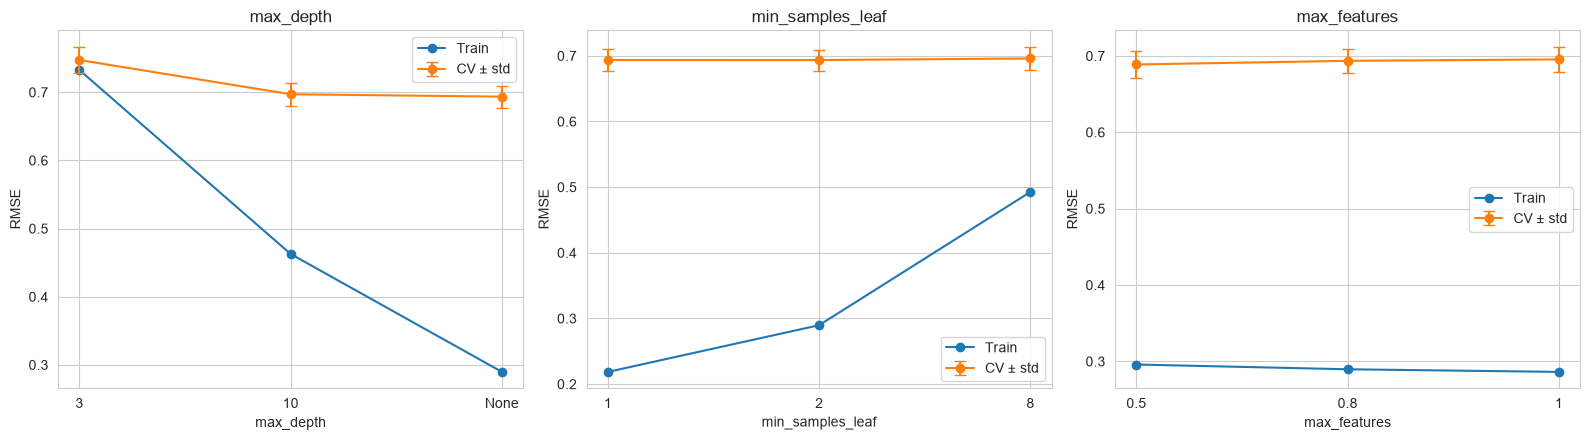

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
baseline_params = baseline.get_params()
influence = {}

for ax, parameter in zip(axes, param_grid):
    mask = pd.Series(True, index=grid_results.index)
    for other in param_grid:
        if other != parameter:
            value = baseline_params[other]
            mask &= grid_results[other].isna() if value is None else grid_results[other].eq(value)
    curve = grid_results.loc[mask].sort_values(parameter, na_position='last')
    influence[parameter] = curve
    labels = ['None' if pd.isna(value) else f'{value:g}' for value in curve[parameter]]
    ax.plot(labels, curve['Train RMSE'], 'o-', label='Train')
    ax.errorbar(labels, curve['CV RMSE'], yerr=curve['CV std'], fmt='o-', capsize=4, label='CV ± std')
    ax.set(xlabel=parameter, ylabel='RMSE', title=parameter)
    ax.legend()

plt.tight_layout()
plt.show()


In [12]:
for parameter, curve in influence.items():
    print('Меняем:', parameter)
    display(curve[[parameter, 'Train RMSE', 'CV RMSE', 'CV std']].round(4))


Меняем: max_depth
Меняем: min_samples_leaf
Меняем: max_features


,max_depth,Train RMSE,CV RMSE,CV std
4,3.0,0.7326,0.7473,0.0195
13,10.0,0.4627,0.6971,0.0170
22,NaN,0.2897,0.6936,0.0160


,min_samples_leaf,Train RMSE,CV RMSE,CV std
21,1,0.2185,0.6936,0.0171
22,2,0.2897,0.6936,0.0160
23,8,0.4927,0.6960,0.0179


,max_features,Train RMSE,CV RMSE,CV std
19,0.5,0.2959,0.6888,0.0175
22,0.8,0.2897,0.6936,0.0160
25,1.0,0.2863,0.6954,0.0166


**Глубина.** При `max_depth=3` Train RMSE = 0.7326 и CV RMSE = 0.7473: ошибки высоки даже на обучении, это область недообучения. При глубине 10 CV RMSE снижается до 0.6971, а без ограничения — до 0.6936. В проверенном срезе рост глубины пока помогает CV, поэтому само значение `None` не доказывает переобучения.

**Размер листа.** При одном объекте Train RMSE = 0.2185, при двух — 0.2897, но CV почти одинаков: 0.69362 и 0.69358. Более точная подгонка train не дала выигрыша вне обучения — это признак избыточной подстройки у самых мелких листьев. Разница CV слишком мала для уверенного вывода о превосходстве одного варианта. При восьми объектах Train RMSE растёт до 0.4927, а CV — до 0.6960: сильное сглаживание тоже не улучшило результат.

**Доля признаков.** При долях 0.5, 0.8 и 1.0 CV RMSE равен 0.6888, 0.6936 и 0.6954 соответственно. Это 6, 9 и 12 признаков из 12 при каждом разбиении. Увеличение доли уменьшает Train RMSE, но ухудшает CV: здесь дополнительная подстройка деревьев мешает обобщению. Результат согласуется с предположением, что большее разнообразие деревьев полезно.

В проверенной сетке разумным сочетанием оказались глубокие деревья, минимум два объекта в листе и половина признаков. Это вывод для выбранных диапазонов: срезы не описывают все возможные взаимодействия параметров.


# Устойчивость результата

Посмотрим на каждый fold отдельно для исходной модели и двух победителей поиска. Новые модели обучать не нужно: эти ошибки уже сохранены при CV. В таблице ниже `std` считается с `ddof=0`, как в `GridSearchCV`.

Две модели с одинаковым средним могут различаться: одна даёт близкие ошибки на всех частях, другая сильно зависит от состава validation. Небольшой разброс предпочтителен при сопоставимом среднем, но пять folds не дают гарантии устойчивости на любых новых данных. Обучающие части folds пересекаются, поэтому их ошибки нельзя считать независимыми повторениями.


,Baseline,Grid Search,Random Search
Fold,,,
1,0.6702,0.6636,0.6698
2,0.6921,0.6882,0.6916
3,0.6958,0.6923,0.6931
4,0.6896,0.6821,0.6852
5,0.7202,0.7178,0.7229


,CV RMSE,CV std,Min,Max
Baseline,0.6936,0.0160,0.6702,0.7202
Grid Search,0.6888,0.0175,0.6636,0.7178
Random Search,0.6925,0.0173,0.6698,0.7229


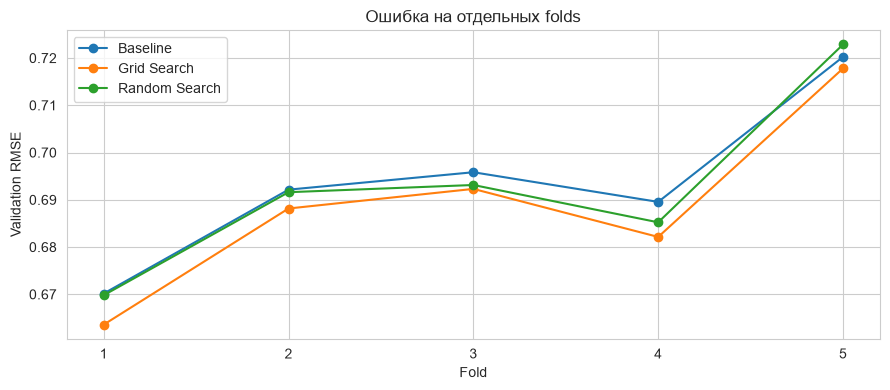

In [13]:
fold_scores = pd.DataFrame({
    'Baseline': -baseline_cv['test_score'],
    'Grid Search': [-grid_search.cv_results_[f'split{i}_test_score'][grid_search.best_index_]
                    for i in range(n_folds)],
    'Random Search': [-random_search.cv_results_[f'split{i}_test_score'][random_search.best_index_]
                      for i in range(n_folds)],
}, index=pd.Index(range(1, n_folds + 1), name='Fold'))
stability = pd.DataFrame({
    'CV RMSE': fold_scores.mean(), 'CV std': fold_scores.std(ddof=0),
    'Min': fold_scores.min(), 'Max': fold_scores.max(),
})
display(fold_scores.round(4))
display(stability.round(4))

fold_scores.plot(marker='o', figsize=(9, 4))
plt.xticks(fold_scores.index)
plt.ylabel('Validation RMSE')
plt.title('Ошибка на отдельных folds')
plt.tight_layout()
plt.show()


Стандартное отклонение исходной модели — 0.0160, Grid Search — 0.0175, Random Search — 0.0173. У Grid Search средняя ошибка ниже baseline на всех пяти folds, но сам разброс немного больше. Значит, лучшее среднее здесь не сопровождается большей устойчивостью по этому показателю.

Пятый fold оказался самым трудным для всех трёх вариантов: их ошибки на нём лежат примерно между 0.718 и 0.723. Это согласуется с влиянием состава валидационной части, общим для моделей. Разброс ошибок по folds нельзя напрямую считать погрешностью разности двух средних: модели сравниваются на одних и тех же частях.

# Выбор настроек и финальное обучение

Из двух результатов поиска выберем меньший средний CV RMSE; при равенстве оставим Grid Search. Baseline тоже сравним до открытия test: если подбор не даст меньшую ошибку, для итогового решения оставим исходную модель. При равенстве baseline имеет приоритет.

После этого обучим все три зафиксированных варианта на всём train и один раз оценим на test, как требует задание. Основное сравнение — RMSE; MAE добавим для интерпретации средней абсолютной ошибки. По тестовым результатам настройки больше не меняем.


In [14]:
searches = {'Grid Search': grid_search, 'Random Search': random_search}
best_search_name = min(searches, key=lambda name: -searches[name].best_score_)
selected_name = stability['CV RMSE'].idxmin()
print('Лучший поиск по CV:', best_search_name)
print('Итоговый вариант по CV:', selected_name)

models = {'Baseline': clone(baseline)}
models.update({name: clone(baseline).set_params(**search.best_params_)
               for name, search in searches.items()})


Лучший поиск по CV: Grid Search
Итоговый вариант по CV: Grid Search


In [15]:
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    rows.append({
        'Модель': name, 'CV RMSE': stability.loc[name, 'CV RMSE'],
        'CV std': stability.loc[name, 'CV std'],
        'Test RMSE': root_mean_squared_error(y_test, prediction),
        'Test MAE': mean_absolute_error(y_test, prediction),
    })

comparison = pd.DataFrame(rows).set_index('Модель')
comparison['Снижение CV RMSE'] = comparison.loc['Baseline', 'CV RMSE'] - comparison['CV RMSE']
comparison['Снижение Test RMSE'] = comparison.loc['Baseline', 'Test RMSE'] - comparison['Test RMSE']
final_model = models[selected_name]
display(comparison.round(5))


,CV RMSE,CV std,Test RMSE,Test MAE,Снижение CV RMSE,Снижение Test RMSE
Модель,,,,,,
Baseline,0.69358,0.01602,0.65290,0.50567,0.00000,0.00000
Grid Search,0.68879,0.01752,0.65281,0.50459,0.00479,0.00010
Random Search,0.69252,0.01727,0.65197,0.50348,0.00106,0.00093


По CV выбран **Grid Search**: RMSE снизился с 0.69358 до 0.68879, то есть на 0.00479 (0.69%). На test ошибка снизилась с 0.65290 до 0.65281: всего на 0.00010. Заметного практического выигрыша по тестовому RMSE в этом разбиении не получилось.

Random Search получил Test RMSE = 0.65197 и Test MAE = 0.50348. На test его RMSE оказался немного ниже, чем у Grid Search, хотя CV предпочла сетку. Порядок двух лучших вариантов не совпал. Итоговую модель из-за этого не меняю: решение уже принято по CV до просмотра тестовых метрик.

Test и CV содержат разные группы объектов, поэтому их ошибки и порядок близких моделей могут отличаться. Кроме того, на каждом fold модель училась на меньшем количестве данных, чем при финальном обучении. Выбор лучшего из множества вариантов также делает его CV-оценку несколько оптимистичной: CV использовалась для подбора.

Эксперимент относится к одному внешнему разбиению и одному запуску случайного поиска. Test не участвовал в выборе настроек этой работы; его прежнее использование в первой ЛР ограничивает независимость итоговой оценки. Полученные различия не доказывают универсального превосходства одной стратегии.
